In [5]:
from coupled_solver.solver import solver

ep_in = 1.
ep_ex = 78.3
k = 0.125

pgb = solver('1pgb/1pgb', ep_in, ep_ex, k)
pgb.solve_vacuum()
pgb.solve_system(grid_scale=1., grid_scale_ratio=2., new_mesh=True, non_linear=True, use_record_info=True)

Reading parameters from amoebapro13.prm
Saved information found. Loading initial dipole.
Volumetric mesh for 1pgb could not be found. Creating...
Malla SES no encontrada para 1pgb. Generando con NanoShaper (Probe Radius: 1.4, Grid Scale: 1.0)...


 <<INFO>> Starting NanoShaper 0.7.8
 <<INFO>> Loading atoms....
 <<INFO>> Read 927 atoms
 <<INFO>> Geometric baricenter ->  8.91805 12.1305 18.5721
 <<INFO>> Grid is 41
 <<INFO>> MAX 28.9181 32.1305 38.5721
 <<INFO>> MIN -11.0819 -7.8695 -1.42793
 <<INFO>> Perfil 90 %
 <<INFO>> Rmaxdim 37.3799
 <<INFO>> Allocating memory...ok!
 <<INFO>> Initialization completed
 <<INFO>> Adjusting self intersection grid 
 <<INFO>> Self intersection grid is (before) 20
 <<INFO>> Self intersection grid is 16
 <<INFO>> Allocating self intersection grid....ok!
 <<INFO>> Computing alpha shape complex....ok!
 <<INFO>> Checking 115 probes for self intersections...ok!
 <<INFO>> Surface build-up time.. 0 [s]
 <<INFO>> Probe Radius value 1.4
 <<INFO>> Number of ses cel

Boundary mesh created: 9464 elements, 4734 vertices
Boundary mesh created: 3208 elements, 1606 vertices
Time to define spaces: 0.19 [s]
FEM dofs: 83071
BEM dofs: 1606
Total dofs: 84677
Saved information found with identical parameters. Loading final dipole.
Time to define potential operators: 0.07 [s]
Time to define boundary and FEM operators: 0.01 [s]
Time to assemble LHS: 0.91 [s]
Time to assembly permanent part of the RHS: 3.76 [s]
------- Dipole iteration 1 -------
Time to solve the harmonic component system: 2.04 [s]
GMRES iter    1 | residual = 4.266e-03
GMRES iter    2 | residual = 3.183e-03
GMRES iter    3 | residual = 2.598e-03
GMRES iter    4 | residual = 2.149e-03
GMRES iter    5 | residual = 1.844e-03
GMRES iter    6 | residual = 1.603e-03
GMRES iter    7 | residual = 1.388e-03
GMRES iter    8 | residual = 1.219e-03
GMRES iter    9 | residual = 1.113e-03
GMRES iter   10 | residual = 1.047e-03
GMRES iter   11 | residual = 9.666e-04
GMRES iter   12 | residual = 9.008e-04
GMRE

In [2]:
pgb.export_potential('surface',filename='1pgb_surface.vtu')
pgb.export_potential('solute', filename='1pgb_solute.vtu')
pgb.export_potential('volume', filename='1pgb_volume.vtu')

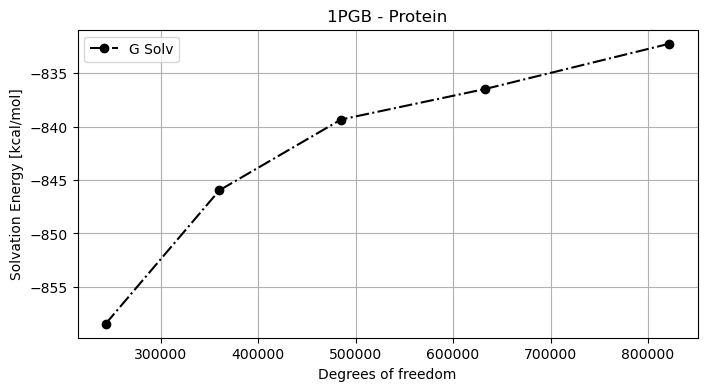

In [3]:
import matplotlib.pyplot as plt
import numpy as np

energy = np.array([-858.4537619016446, -845.9607025926889, -839.3310232685071, -836.4805546394018, -832.235192336535])
ndofs = np.array([243715., 360310., 485140., 632572., 821822.])

fig, ax1= plt.subplots(figsize=(8, 4))
ax1.plot(ndofs, energy, label ='G Solv', linestyle="-.",color="black", marker="o")
ax1.set_xlabel('Degrees of freedom')
ax1.set_ylabel('Solvation Energy [kcal/mol]')
ax1.set_title('1PGB - Protein')
ax1.grid(True)
ax1.legend()